# 04 - Fine-tuning loss curves: 800x160x32 vs 1600x320x64

Train and validation curves of the LoRA-32 fine-tuning ([`experiments/03_autoencoder-fine-tuning-with-lora_partial`](../experiments/03_autoencoder-fine-tuning-with-lora_partial)).
Latent scale 2 = 800x160x32, latent scale 4 = 1600x320x64.

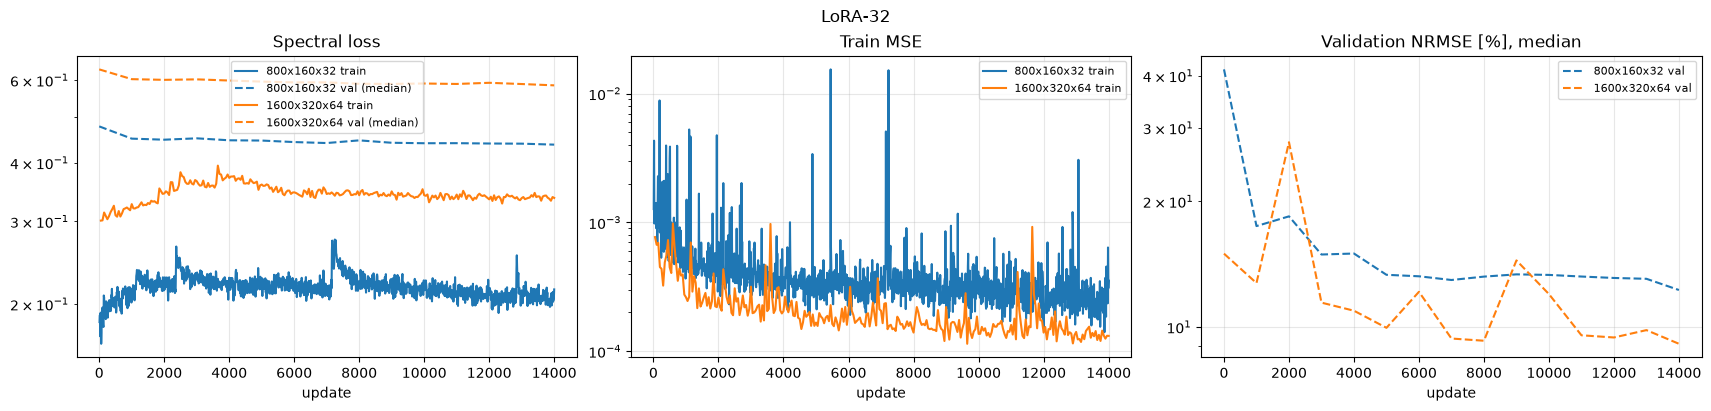

In [1]:
import matplotlib.pyplot as plt
import polars as pl

from coolfrog.lib.experiment import PATH_EXPERIMENTS, pull_experiment
from coolfrog.lib.huggingface import HuggingFaceHub

PATH_EXPERIMENT = PATH_EXPERIMENTS / "03_autoencoder-fine-tuning-with-lora_partial"
RESOLUTIONS = {2: "800x160x32", 4: "1600x320x64"}

if not (PATH_EXPERIMENT / "results/latent_scale_2/metrics.parquet").exists():
    pull_experiment(HuggingFaceHub(), PATH_EXPERIMENT)  # metrics.parquet lives on Hugging Face
metrics = {scale: pl.read_parquet(PATH_EXPERIMENT / f"results/latent_scale_{scale}/metrics.parquet") for scale in RESOLUTIONS}

panels = [  # (title, [(metric, linestyle, label)])
    ("Spectral loss", [("train/spectral_loss", "-", "train"), ("val/spectral_loss", "--", "val (median)")]),
    ("Train MSE", [("train/mse", "-", "train")]),
    ("Validation NRMSE [%], median", [("val/nrmse", "--", "val")]),
]
figure, axes = plt.subplots(1, len(panels), figsize=(17, 4), layout="constrained")
for axis, (title, series) in zip(axes, panels):
    for (scale, resolution), color in zip(RESOLUTIONS.items(), ("C0", "C1")):
        for metric, linestyle, label in series:
            data = metrics[scale].select("update", metric).drop_nulls()
            axis.plot(data["update"], data[metric], linestyle, color=color, label=f"{resolution} {label}")
    axis.set(title=title, xlabel="update", yscale="log")
    axis.grid(alpha=0.3)
    axis.legend(fontsize=8)
figure.suptitle("LoRA-32")
plt.show()

## Per channel, KL and cost

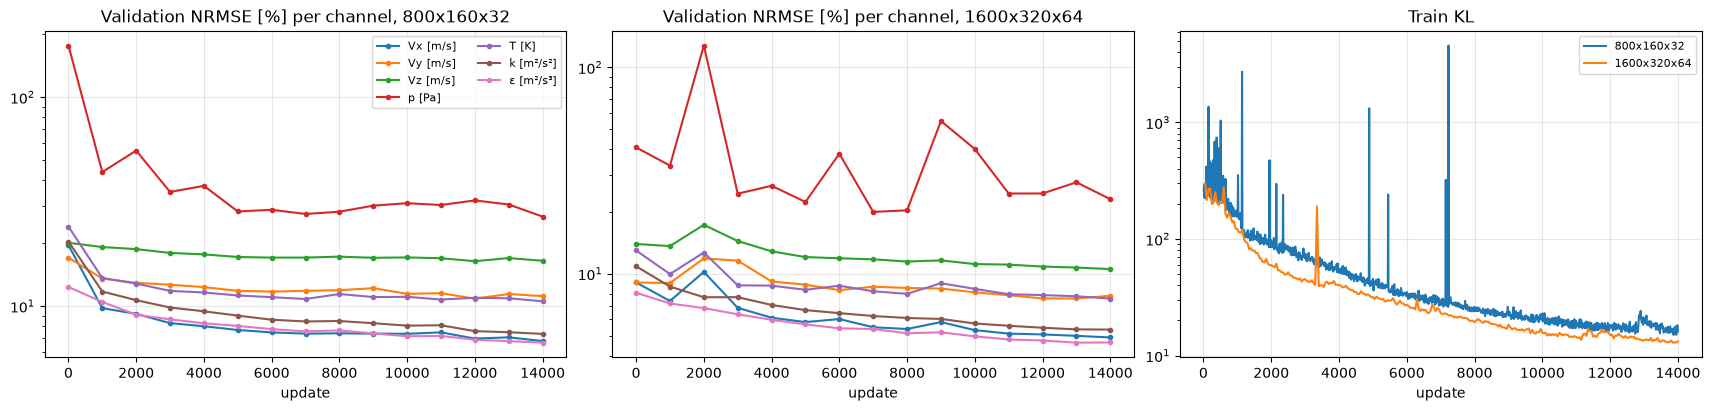

resolution,zero-shot mean [%],final mean [%],training time [h]
str,f64,f64,f64
"""800x160x32""",41.418144,12.258937,0.143705
"""1600x320x64""",14.982018,9.110892,0.186996


In [2]:
from coolfrog.lib.datatypes import CHANNELS

figure, axes = plt.subplots(1, 3, figsize=(17, 4), layout="constrained")
for axis, (scale, resolution) in zip(axes[:2], RESOLUTIONS.items()):
    for channel in CHANNELS:
        name = f"val/nrmse/{channel.value}"
        data = metrics[scale].select("update", name).drop_nulls()
        axis.plot(data["update"], data[name], marker="o", markersize=3, label=channel.value)
    axis.set(title=f"Validation NRMSE [%] per channel, {resolution}", xlabel="update", yscale="log")
    axis.grid(alpha=0.3)
axes[0].legend(fontsize=8, ncols=2)
for scale, resolution in RESOLUTIONS.items():
    data = metrics[scale].select("update", "train/kl").drop_nulls()
    axes[2].plot(data["update"], data["train/kl"], label=resolution)
axes[2].set(title="Train KL", xlabel="update", yscale="log")
axes[2].grid(alpha=0.3)
axes[2].legend(fontsize=8)
plt.show()

rows = []
for scale, resolution in RESOLUTIONS.items():
    validation = metrics[scale].select("update", *(f"val/nrmse/{channel.value}" for channel in CHANNELS)).drop_nulls()
    rows.append({
        "resolution": resolution,
        "NRMSE zero-shot [%]": validation.row(0)[1:],
        "NRMSE final [%]": validation.row(-1)[1:],
        "training time [h]": metrics[scale]["train/seconds_per_update"].drop_nulls().sum() / 3600,
    })
summary = pl.DataFrame(rows)
summary.with_columns(
    pl.col("NRMSE zero-shot [%]").list.mean().alias("zero-shot mean [%]"),
    pl.col("NRMSE final [%]").list.mean().alias("final mean [%]"),
).select("resolution", "zero-shot mean [%]", "final mean [%]", "training time [h]")